In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")


In [5]:
df.columns = [col.strip().replace(" ", "_").replace(".", "").lower() for col in df.columns]
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isbestseller',
       'boughtinlastmonth', 'category'],
      dtype='object')

In [11]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [13]:
df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [15]:
df.shape

(2443651, 9)

In [23]:
category_frequency = df['category'].value_counts()
print(category_frequency)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64


In [27]:
category_proportion = df['category'].value_counts(normalize=True)
category_proportion

category
Sports & Outdoors                         0.342219
Beauty                                    0.007903
Handmade Clothing, Shoes & Accessories    0.007869
Bath & Body                               0.007813
Birthday Gifts                            0.007766
                                            ...   
Alexa Built-In Devices                    0.000044
Motorbike Chassis                         0.000044
Plugs                                     0.000044
Smart Home Security & Lighting            0.000043
Smart Speakers                            0.000022
Name: proportion, Length: 296, dtype: float64

In [25]:
top_5_categories = category_frequency.head(5)
print(top_5_categories)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


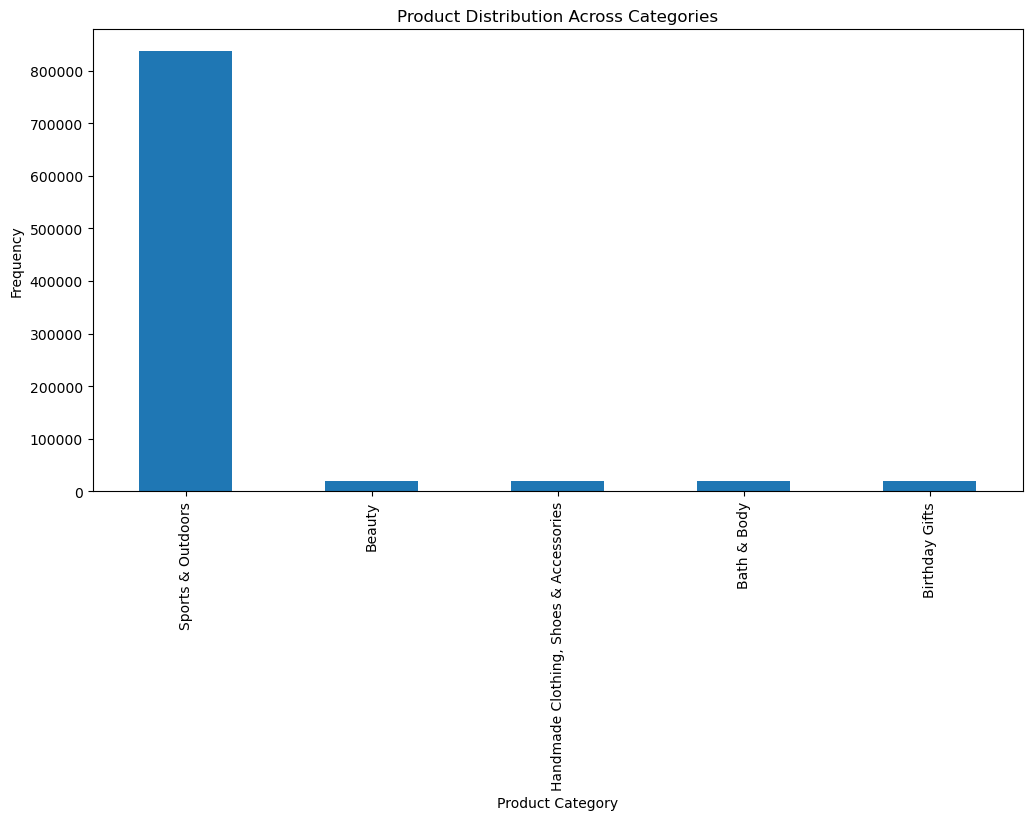

In [31]:
plt.figure(figsize=(12,6))
top_5_categories.plot(kind='bar')
plt.title('Product Distribution Across Categories')
plt.xlabel('Product Category')
plt.ylabel('Frequency')
plt.show()

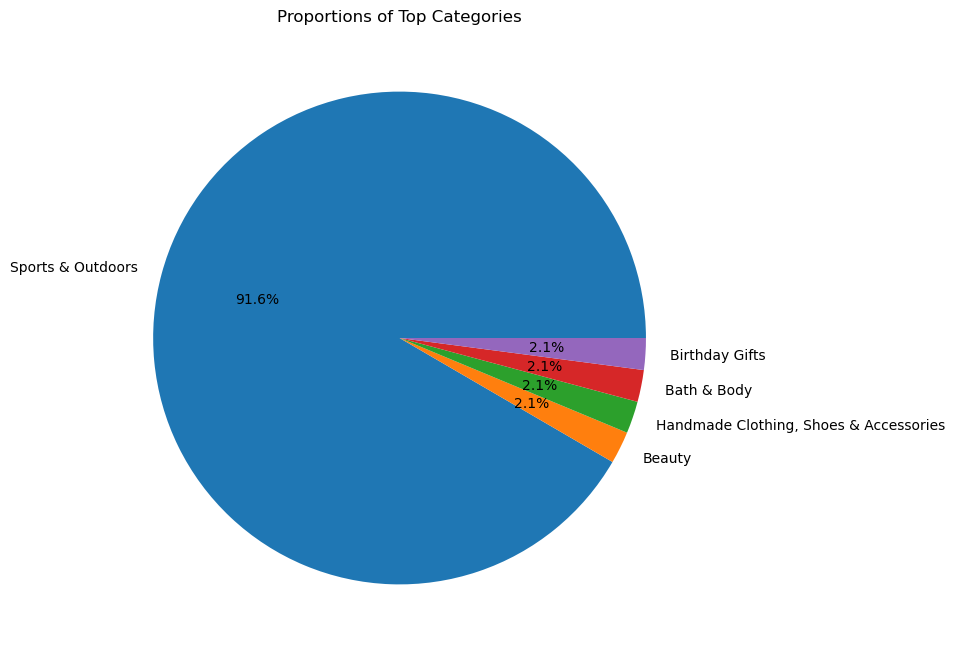

In [85]:
# Subset of top categories
top_5_categories_subset = ['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories', 'Bath & Body', 'Birthday Gifts']

# Get the number of listings for the subset of top categories
listings_subset = df['category'].loc[df['category'].isin(top_5_categories_subset)]

# Count the number of listings for each category
category_counts = listings_subset.value_counts()

# Visualize the proportions using a pie chart
plt.figure(figsize=(8, 8))
plt.pie(category_counts, labels=category_counts.index, autopct='%1.1f%%')
plt.title('Proportions of Top Categories')
plt.show()

In [69]:
#PART 2 measures of centrality
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()

print("Mean price:", mean_price)
print("Median price:", median_price)
print("Mode price:", mode_price)

Mean price: 89.24380943923663
Median price: 19.09
Mode price: 0    9.99
Name: price, dtype: float64


In [39]:
variance_price = df['price'].var()
std_dev_price = df['price'].std()
price_range = df['price'].max() - df['price'].min()
interquartile_range_price = df['price'].quantile(0.75) - df['price'].quantile(0.25)

print("Variance of price:", variance_price)
print("Standard deviation of price:", std_dev_price)
print("Range of price:", price_range)
print("Interquartile range of price:", interquartile_range_price)

Variance of price: 119445.48532256528
Standard deviation of price: 345.60886175352226
Range of price: 100000.0
Interquartile range of price: 36.0


C:\Users\Ricardo\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


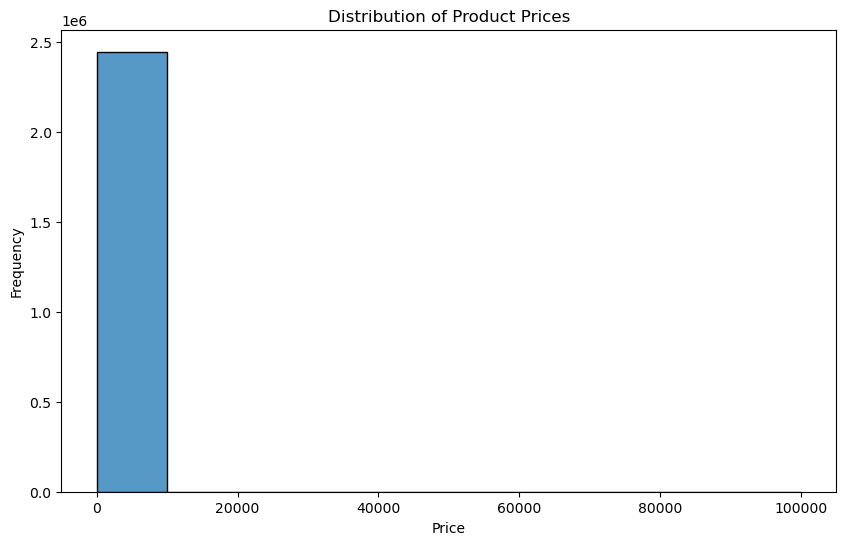

In [57]:
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], kde=False, bins=10)
plt.title('Distribution of Product Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

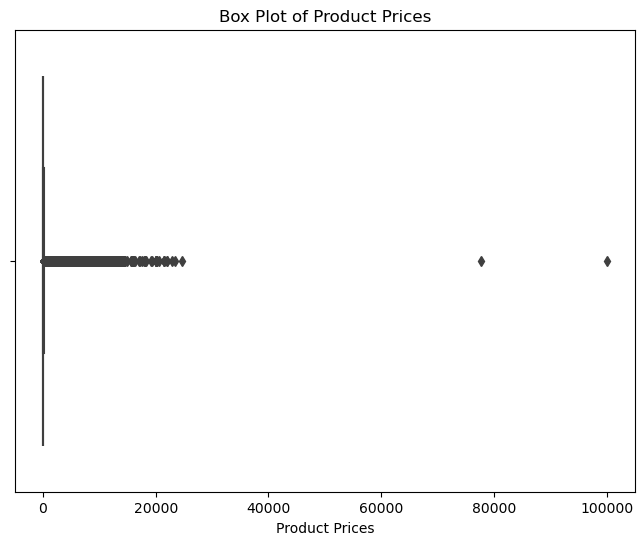

In [49]:
plt.figure(figsize=(8, 6))
sns.boxplot(x=df['price'])
plt.title('Box Plot of Product Prices')
plt.xlabel('Product Prices')
plt.show()

In [ ]:
#There are products that are significantly higher priced than the rest as we can observe.

In [71]:
#PART 3 UNPACKING PRODUCT RATINGS
mean_stars = df['stars'].mean()
median_stars = df['stars'].median()
mode_stars = df['stars'].mode()

print("Mean stars:", mean_stars)
print("Median stars:", median_stars)
print("Mode stars:", mode_stars)


Mean stars: 2.152836472966065
Median stars: 0.0
Mode stars: 0    0.0
Name: stars, dtype: float64


In [73]:
variance_stars = df['stars'].var()
std_dev_stars = df['stars'].std()
interquartile_range_stars = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

print("Variance of stars:", variance_stars)
print("Standard deviation of stars:", std_dev_stars)
print("Interquartile range of stars:", interquartile_range_stars)

Variance of stars: 4.81743402976196
Standard deviation of stars: 2.1948653785054697
Interquartile range of stars: 4.4


In [75]:
# Calculate the skewness and kurtosis for the rating column
skewness_stars = df['stars'].skew()
kurtosis_stars = df['stars'].kurt()

print("Skewness of stars:", skewness_stars)
print("Kurtosis of stars:", kurtosis_stars)

Skewness of stars: 0.08120735761080985
Kurtosis of stars: -1.9260061280432985


C:\Users\Ricardo\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


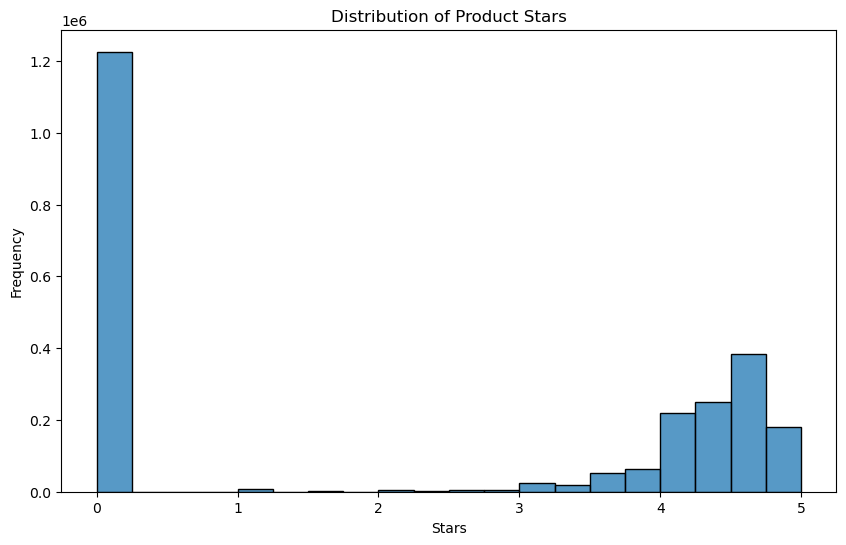

In [79]:
# Plot a histogram to visualize the distribution of product ratings
plt.figure(figsize=(10, 6))
sns.histplot(df['stars'], kde=False, bins=20)
plt.title('Distribution of Product Stars')
plt.xlabel('Stars')
plt.ylabel('Frequency')
plt.show()